# Estimating entropy from finite samples

Shannon entropy is the probability-weighted average surprise of a discrete symbol, measured in bits:

$$
H(X)=-\sum_{x\in\mathcal A}p(x)\log_2 p(x),
\qquad
0\leq H(X)\leq\log_2|\mathcal A|.
$$

Here, $X$ is a discrete random variable; $\mathcal A$ is its alphabet; $x$ is one possible symbol. $p(x)$ is the probability of $x$; $H(X)$ is entropy; $|\mathcal A|$ is alphabet size; $\log_2$ uses base two.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as ss
from IPython.display import Image
from sklearn.metrics import mutual_info_score

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.data.distance import distance_correlation, ksg_mutual_information
from RiskLabAI.data.distance.distance_metric import calculate_distance, calculate_mutual_information, calculate_number_of_bins, calculate_variation_of_information, calculate_variation_of_information_extended
from RiskLabAI.features.entropy_features import grassberger_entropy, miller_madow_entropy, nsb_entropy
from RiskLabAI.features.entropy_features.kontoyiannis import kontoyiannis_entropy
from RiskLabAI.features.entropy_features.lempel_ziv import lempel_ziv_entropy
from RiskLabAI.features.entropy_features.plug_in import plug_in_entropy_estimator
from RiskLabAI.features.entropy_features.pmf import probability_mass_function
from RiskLabAI.features.entropy_features.shannon import shannon_entropy

FIGURES = ROOT / "outputs" / "figures" / "09_dependence_geometry_information"
TABLES = ROOT / "outputs" / "tables" / "09_dependence_geometry_information"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

raw = raw.sort_values("time").dropna(subset=["time", "close"]).drop_duplicates("time").reset_index(drop=True)
minute_close = pd.Series(raw["close"].to_numpy(dtype=float), index=pd.DatetimeIndex(raw["time"]), name="One-minute close")
close = minute_close.resample("15min").last().dropna().rename("Fifteen-minute close")
log_price = np.log(close).rename("Log price")
returns = log_price.diff().dropna().rename("Fifteen-minute log return")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Encoding Public Returns

In [2]:
direction_message = "".join(np.where(returns.to_numpy() >= 0.0, "U", "D"))
return_bins = pd.qcut(returns.rank(method="first"), 3, labels=["L", "M", "H"])
return_state_message = "".join(return_bins.astype(str))
volatility_bins = pd.qcut(returns.abs().rank(method="first"), 3, labels=["L", "M", "H"])
volatility_state_message = "".join(volatility_bins.astype(str))
messages = {
    "Return direction": direction_message,
    "Return tercile": return_state_message,
    "Absolute-return tercile": volatility_state_message,
}
entropy_rows = []
for label, message in messages.items():
    entropy_rows.append({"Encoding": label, "Symbols": len(set(message)), "Message length": len(message), "Shannon entropy": shannon_entropy(message), "Plug-in entropy for pairs": plug_in_entropy_estimator(message, 2), "Lempel-Ziv dictionary rate": lempel_ziv_entropy(message), "Kontoyiannis entropy with window 64": kontoyiannis_entropy(message, window=64)})
entropy_public_summary = pd.DataFrame(entropy_rows)
ngram_rows = []
for word_length in range(1, 7):
    pmf = probability_mass_function(direction_message, word_length)
    ngram_rows.append({"Word length": word_length, "Observed words": len(pmf), "Possible binary words": 2 ** word_length, "Observed share": len(pmf) / (2 ** word_length), "Plug-in entropy per symbol": plug_in_entropy_estimator(direction_message, word_length)})
ngram_summary = pd.DataFrame(ngram_rows)
rolling_rows = []
window = 512
step = 128
for end in range(window, len(direction_message) + 1, step):
    segment = direction_message[end - window:end]
    rolling_rows.append({"End time": str(returns.index[end - 1]), "Window observations": window, "Plug-in entropy for pairs": plug_in_entropy_estimator(segment, 2), "Kontoyiannis entropy with window 64": kontoyiannis_entropy(segment, window=64)})
rolling_entropy = pd.DataFrame(rolling_rows)
entropy_window_summary = pd.DataFrame({
    "Summary": ["First", "Smallest", "Middle value", "Mean", "Largest", "Last"],
    "Plug-in entropy for pairs": [rolling_entropy["Plug-in entropy for pairs"].iloc[0], rolling_entropy["Plug-in entropy for pairs"].min(), rolling_entropy["Plug-in entropy for pairs"].median(), rolling_entropy["Plug-in entropy for pairs"].mean(), rolling_entropy["Plug-in entropy for pairs"].max(), rolling_entropy["Plug-in entropy for pairs"].iloc[-1]],
    "Kontoyiannis entropy with window 64": [rolling_entropy["Kontoyiannis entropy with window 64"].iloc[0], rolling_entropy["Kontoyiannis entropy with window 64"].min(), rolling_entropy["Kontoyiannis entropy with window 64"].median(), rolling_entropy["Kontoyiannis entropy with window 64"].mean(), rolling_entropy["Kontoyiannis entropy with window 64"].max(), rolling_entropy["Kontoyiannis entropy with window 64"].iloc[-1]],
})
save_table(entropy_public_summary, "entropy_public_summary", "Entropy and compression measures for three encodings of public returns.", "tab:chapter8-entropy-public", fit=True)
save_table(ngram_summary, "ngram_summary", "Observed binary words and plug-in entropy by word length.", "tab:chapter8-ngram-summary", fit=True)
save_table(entropy_window_summary, "entropy_window_summary", "Rolling entropy summaries for the public direction message.", "tab:chapter8-entropy-window", fit=True)
display(entropy_public_summary.round(6))
display(ngram_summary.round(6))
display(entropy_window_summary.round(6))

,Encoding,Symbols,Message length,Shannon entropy,Plug-in entropy for pairs,Lempel-Ziv dictionary rate,Kontoyiannis entropy with window 64
0,Return direction,2,2975,0.999998,0.999449,0.142185,0.856762
1,Return tercile,3,2975,1.584962,1.581334,0.190924,1.291095
2,Absolute-return tercile,3,2975,1.584962,1.578733,0.189244,1.280076


,Word length,Observed words,Possible binary words,Observed share,Plug-in entropy per symbol
0,1,2,2,1,0.999998
1,2,4,4,1,0.999449
2,3,8,8,1,0.998681
3,4,16,16,1,0.997607
4,5,32,32,1,0.996863
5,6,64,64,1,0.995449


,Summary,Plug-in entropy for pairs,Kontoyiannis entropy with window 64
0,First,0.993822,0.859550
1,Smallest,0.993822,0.833796
2,Middle value,0.998514,0.867681
3,Mean,0.998287,0.866505
4,Largest,0.999774,0.904302
5,Last,0.997598,0.867961


## Estimating entropy from compression

The plug-in estimate uses observed word frequencies, while the Lempel-Ziv rate records how many new substrings appear per symbol:

$$
\widehat H_{N,w}
=-\frac{1}{w}\sum_{a\in\mathcal A^w}\widehat p_w(a)\log_2\widehat p_w(a),
\qquad
C_{\mathrm{LZ}}=\frac{|\mathcal D_{\mathrm{LZ}}|}{N}.
$$

Here, $N$ is message length; $w$ is word length; $\mathcal A^w$ is the set of possible length-$w$ words. $\widehat p_w(a)$ is the observed frequency of word $a$; $\mathcal D_{\mathrm{LZ}}$ is the parsed substring dictionary; $|\cdot|$ counts elements.

The Kontoyiannis calculation assigns more entropy when new substrings remain short relative to the available history:

$$
\widehat H_{\mathrm K}
=\frac{1}{|\mathcal I|}\sum_{i\in\mathcal I}\frac{\log_2 n_i}{L_i},
\qquad
L_i=1+\max\{\ell:\text{the length-}\ell\text{ word at }i\text{ appears in the preceding }n_i\text{ symbols}\}.
$$

Here, $\mathcal I$ is the set of evaluated positions; $i$ is one position; $n_i$ is its look-back length. $L_i$ is one plus the longest preceding match length; $\ell$ is a candidate match length; $\widehat H_{\mathrm K}$ is the estimated entropy rate.

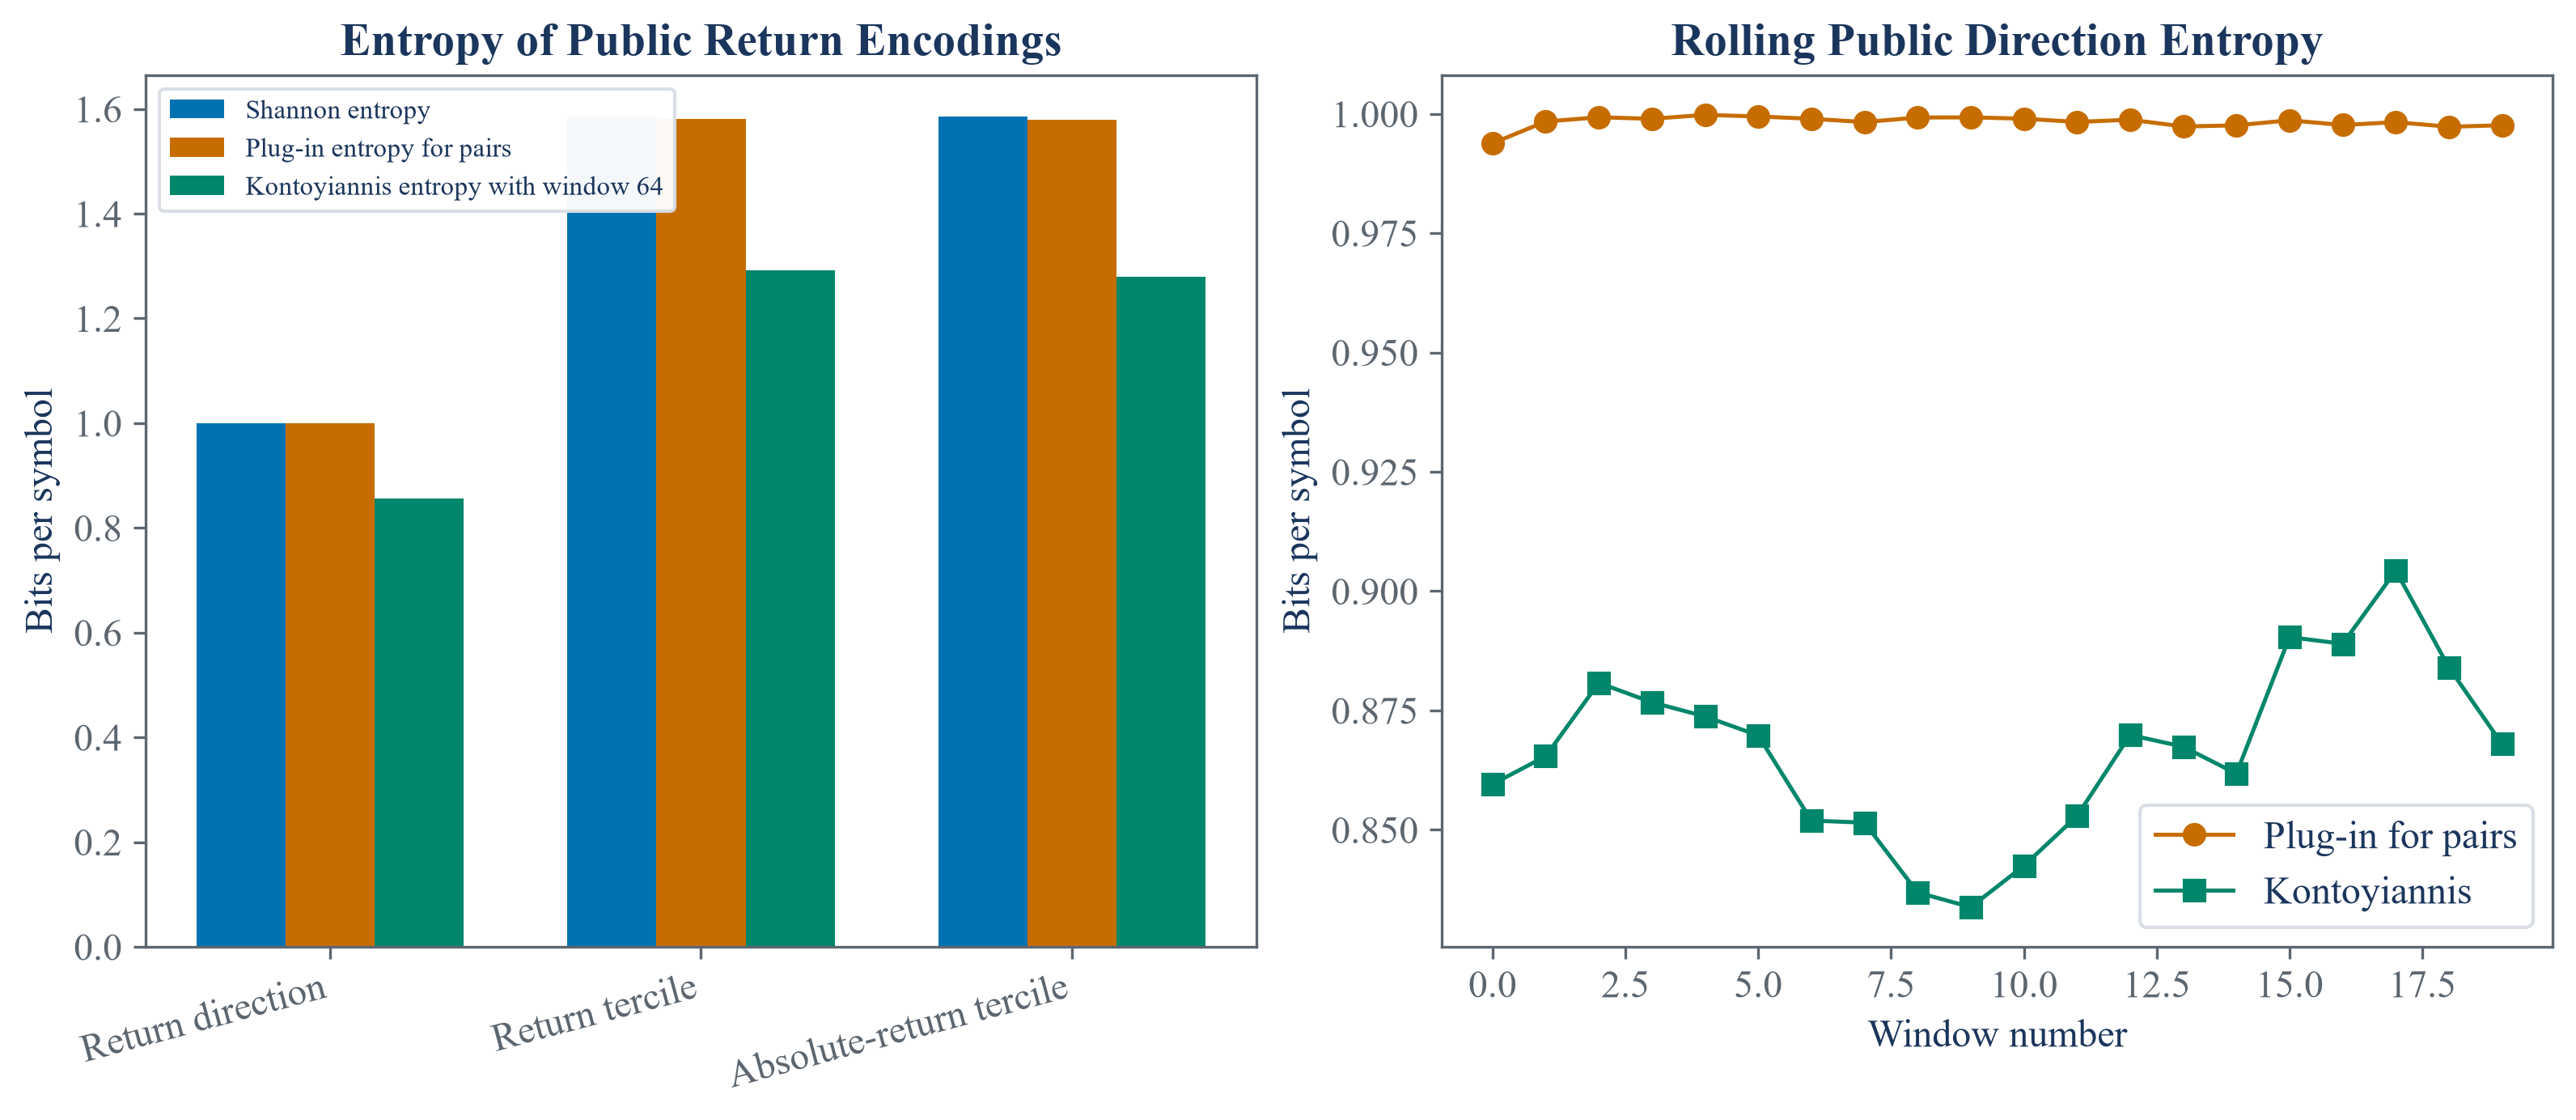

In [3]:
figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
positions = np.arange(len(entropy_public_summary))
width = 0.24
for offset, column, color in [(-width, "Shannon entropy", palette["cyan"]), (0.0, "Plug-in entropy for pairs", palette["amber"]), (width, "Kontoyiannis entropy with window 64", palette["green"])]:
    axes[0].bar(positions + offset, entropy_public_summary[column], width=width, label=column, color=color)
axes[0].set_xticks(positions, entropy_public_summary["Encoding"], rotation=15, ha="right")
axes[0].set_title("Entropy of Public Return Encodings")
axes[0].set_ylabel("Bits per symbol")
axes[0].legend(fontsize=8)
axes[1].plot(rolling_entropy.index, rolling_entropy["Plug-in entropy for pairs"], marker="o", color=palette["amber"], linewidth=1.2, label="Plug-in for pairs")
axes[1].plot(rolling_entropy.index, rolling_entropy["Kontoyiannis entropy with window 64"], marker="s", color=palette["green"], linewidth=1.2, label="Kontoyiannis")
axes[1].set_title("Rolling Public Direction Entropy")
axes[1].set_xlabel("Window number")
axes[1].set_ylabel("Bits per symbol")
axes[1].legend()
figure.savefig(FIGURES / "public_entropy_comparison.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_entropy_comparison.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_entropy_comparison.png")))
plt.close(figure)

## Finite Samples with Known Truth

A sample cannot display more distinct symbols than its size, so the plug-in estimate has a strict ceiling when the true alphabet is larger than the sample:

$$
\widehat H_N\leq\log_2\!\bigl(\min\{K,N\}\bigr),
\qquad
H_{\mathrm{uniform}}=\log_2 K.
$$

Here, $\widehat H_N$ is plug-in entropy from $N$ observations; $K$ is the true alphabet size. $H_{\mathrm{uniform}}$ is the true entropy of equally likely symbols; $\min\{K,N\}$ is the smaller of alphabet and sample size.

,Sample size,True entropy,Mean plug-in estimate,Estimated bias,Root mean squared error,Maximum possible sample estimate
0,8,4,2.586152,-1.413848,1.436778,3
1,12,4,2.973399,-1.026601,1.047696,3.584963
2,16,4,3.206626,-0.793374,0.818608,4
3,24,4,3.443705,-0.556295,0.579778,4
4,40,4,3.692943,-0.307057,0.324891,4
5,80,4,3.861156,-0.138844,0.148321,4
6,160,4,3.934502,-0.065498,0.069625,4
7,320,4,3.964266,-0.035734,0.038333,4
8,640,4,3.982537,-0.017463,0.018471,4
9,1280,4,3.991170,-0.008830,0.009332,4


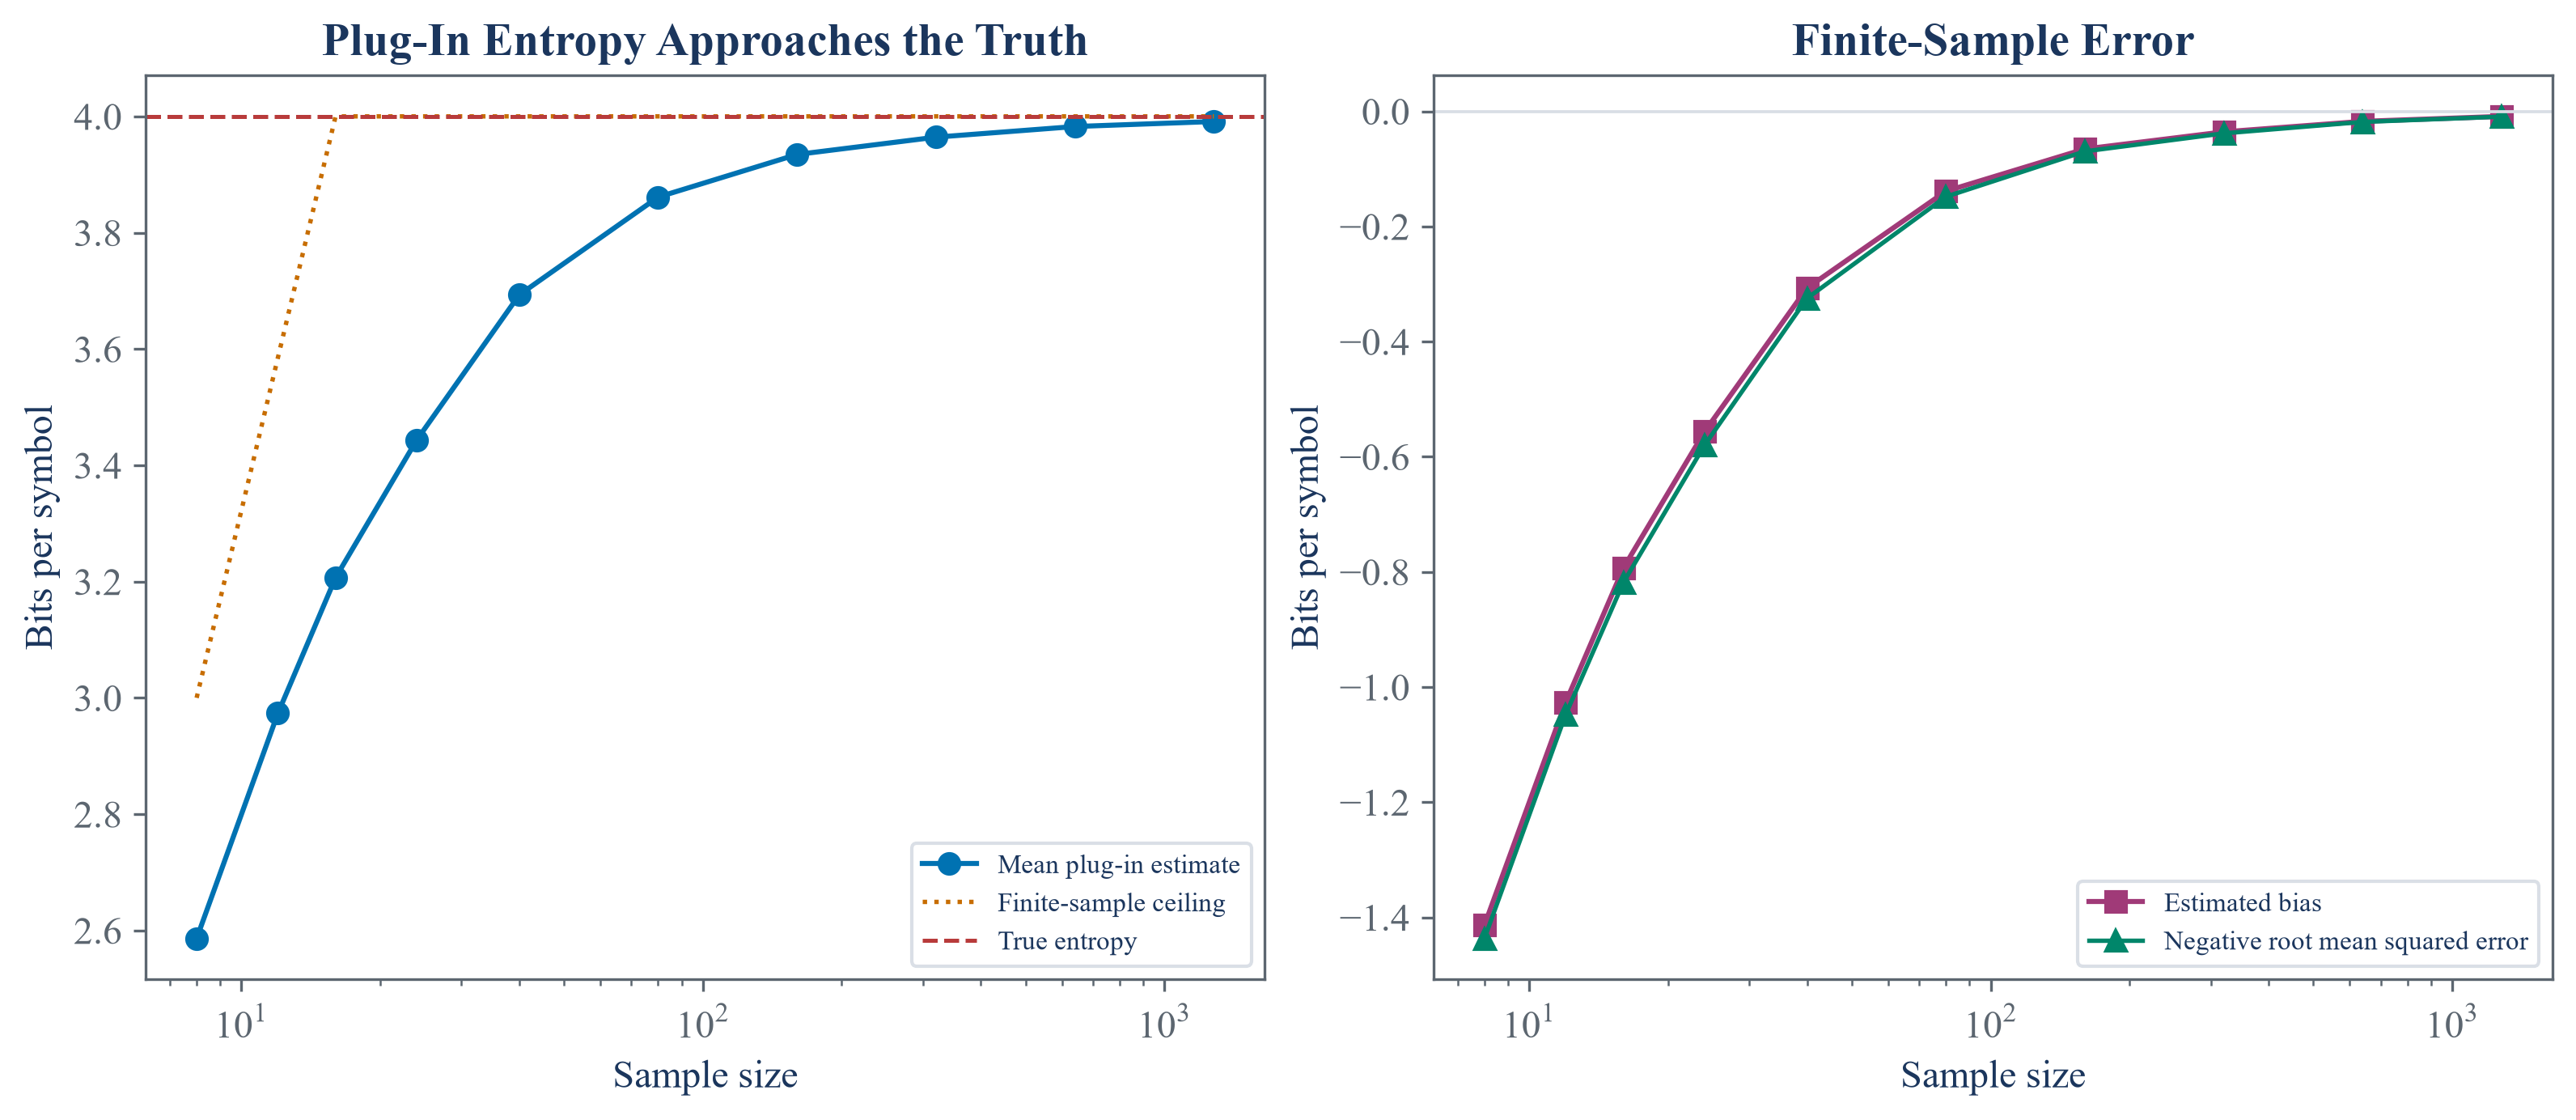

In [4]:
alphabet_size = 16
alphabet = list("0123456789ABCDEF")
true_entropy = np.log2(alphabet_size)
simulation_rows = []
stored_estimates = {}
for sample_size in [8, 12, 16, 24, 40, 80, 160, 320, 640, 1280]:
    estimates = []
    for repetition in range(200):
        rng = np.random.default_rng(8000 + 1000 * sample_size + repetition)
        message = "".join(rng.choice(alphabet, size=sample_size))
        estimates.append(plug_in_entropy_estimator(message, 1))
    estimates = np.asarray(estimates)
    stored_estimates[sample_size] = estimates
    simulation_rows.append({"Sample size": sample_size, "True entropy": true_entropy, "Mean plug-in estimate": estimates.mean(), "Estimated bias": estimates.mean() - true_entropy, "Root mean squared error": np.sqrt(np.mean((estimates - true_entropy) ** 2)), "Maximum possible sample estimate": np.log2(min(alphabet_size, sample_size))})
plugin_bias_summary = pd.DataFrame(simulation_rows)
save_table(plugin_bias_summary, "plugin_bias_summary", "Plug-in entropy error for simulated uniform symbols with known truth.", "tab:chapter8-plugin-bias", fit=True)
display(plugin_bias_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
axes[0].plot(plugin_bias_summary["Sample size"], plugin_bias_summary["Mean plug-in estimate"], marker="o", color=palette["cyan"], linewidth=1.5, label="Mean plug-in estimate")
axes[0].plot(plugin_bias_summary["Sample size"], plugin_bias_summary["Maximum possible sample estimate"], linestyle=":", color=palette["amber"], linewidth=1.3, label="Finite-sample ceiling")
axes[0].axhline(true_entropy, color=palette["rose"], linestyle="--", linewidth=1.2, label="True entropy")
axes[0].set_xscale("log")
axes[0].set_title("Plug-In Entropy Approaches the Truth")
axes[0].set_xlabel("Sample size")
axes[0].set_ylabel("Bits per symbol")
axes[0].legend(fontsize=8)
axes[1].plot(plugin_bias_summary["Sample size"], plugin_bias_summary["Estimated bias"], marker="s", color=palette["violet"], linewidth=1.5, label="Estimated bias")
axes[1].plot(plugin_bias_summary["Sample size"], -plugin_bias_summary["Root mean squared error"], marker="^", color=palette["green"], linewidth=1.3, label="Negative root mean squared error")
axes[1].axhline(0.0, color=palette["grid"], linewidth=0.9)
axes[1].set_xscale("log")
axes[1].set_title("Finite-Sample Error")
axes[1].set_xlabel("Sample size")
axes[1].set_ylabel("Bits per symbol")
axes[1].legend(fontsize=8)
figure.savefig(FIGURES / "plugin_entropy_bias.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "plugin_entropy_bias.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "plugin_entropy_bias.png")))
plt.close(figure)

## Bias Corrections for Sparse Counts

The Miller-Madow estimate adds a first correction for symbols that a short sample may miss:

$$
\widehat H_{\mathrm{MM}}
=\widehat H_{\mathrm{plug}}
+\frac{\widehat K-1}{2N\ln 2}.
$$

Here, $\widehat H_{\mathrm{MM}}$ is the corrected entropy in bits; $\widehat H_{\mathrm{plug}}$ is the observed-frequency estimate. $\widehat K$ is the number of observed symbols; $N$ is the number of observations; $\ln 2$ converts natural-log units to bits.

,Sample size,Method,True entropy,Mean estimate,Estimated bias,Root mean squared error
0,40,Plug-in,4,3.693080,-0.306920,0.325961
1,40,Miller-Madow,4,3.947055,-0.052945,0.134494
2,40,Grassberger,4,4.055685,0.055685,0.171445
3,40,NSB,4,3.843123,-0.156877,0.165782
4,80,Plug-in,4,3.855796,-0.144204,0.150890
5,80,Miller-Madow,4,3.990298,-0.009702,0.047254
6,80,Grassberger,4,4.009617,0.009617,0.059544
7,80,NSB,4,3.911506,-0.088494,0.090978
8,160,Plug-in,4,3.928039,-0.071961,0.074807
9,160,Miller-Madow,4,3.995665,-0.004335,0.020893


,Sample size,Method,True entropy,Mean estimate,Absolute bias
0,40,Plug-in,1,0.977234,0.022766
1,40,Miller-Madow,1,0.995268,0.004732
2,40,Grassberger,1,1.013597,0.013597
3,40,NSB,1,0.965757,0.034243
4,200,Plug-in,1,0.997067,0.002933
5,200,Miller-Madow,1,1.000673,0.000673
6,200,Grassberger,1,1.005501,0.005501
7,200,NSB,1,0.993793,0.006207


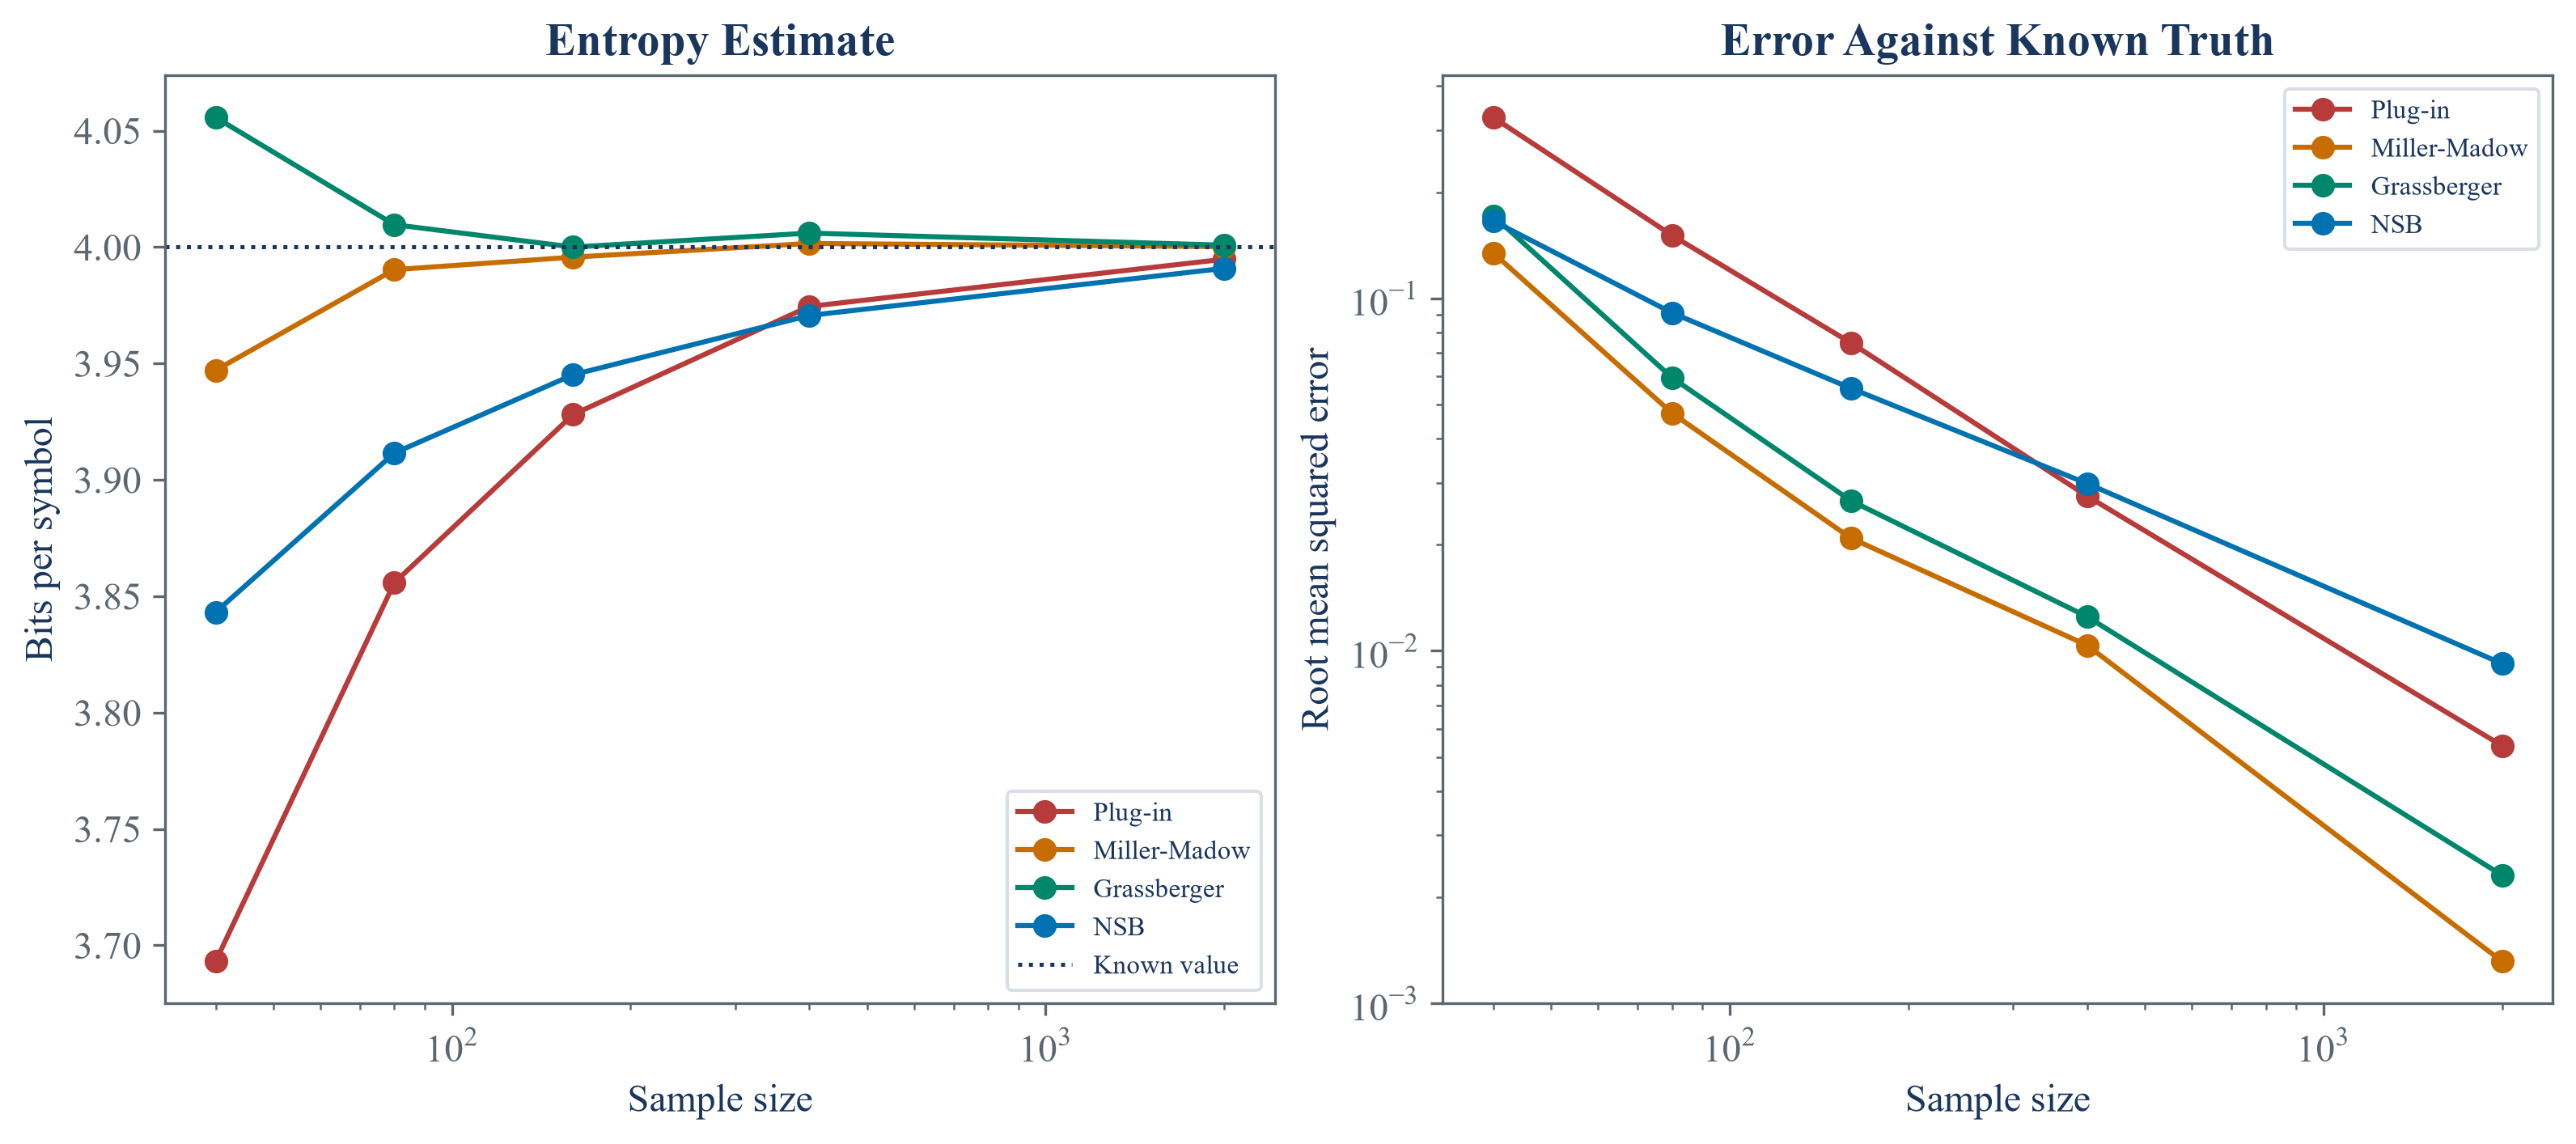

In [5]:
def random_uniform_message(symbol_count, message_length, seed):
    random_generator = np.random.default_rng(seed)
    available_symbols = list("0123456789abcdefghijklmnopqrstuvwxyz"[:symbol_count])
    return "".join(random_generator.choice(available_symbols, size=message_length))

corrected_sample_sizes = [40, 80, 160, 400, 2000]
corrected_methods = {
    "Plug-in": lambda message, symbol_count: plug_in_entropy_estimator(message, 1),
    "Miller-Madow": lambda message, symbol_count: miller_madow_entropy(message, 1),
    "Grassberger": lambda message, symbol_count: grassberger_entropy(message, 1),
    "NSB": lambda message, symbol_count: nsb_entropy(message, 1, alphabet_size=symbol_count),
}
corrected_runs = []
for sample_size in corrected_sample_sizes:
    for seed in range(12):
        message = random_uniform_message(alphabet_size, sample_size, seed)
        for method, estimator in corrected_methods.items():
            estimate = estimator(message, alphabet_size)
            corrected_runs.append({"Sample size": sample_size, "Seed": seed, "Method": method, "Estimate": estimate, "Error": estimate - true_entropy})
bias_corrected_runs = pd.DataFrame(corrected_runs)
corrected_rows = []
for (sample_size, method), group in bias_corrected_runs.groupby(["Sample size", "Method"], sort=False):
    corrected_rows.append({"Sample size": sample_size, "Method": method, "True entropy": true_entropy, "Mean estimate": group["Estimate"].mean(), "Estimated bias": group["Error"].mean(), "Root mean squared error": np.sqrt(np.mean(group["Error"] ** 2))})
bias_corrected_summary = pd.DataFrame(corrected_rows)

binary_rows = []
for sample_size in [40, 200]:
    for method, estimator in corrected_methods.items():
        values = [estimator(random_uniform_message(2, sample_size, seed), 2) for seed in range(12)]
        binary_rows.append({"Sample size": sample_size, "Method": method, "True entropy": 1.0, "Mean estimate": np.mean(values), "Absolute bias": abs(np.mean(values) - 1.0)})
coarse_alphabet_summary = pd.DataFrame(binary_rows)
save_table(bias_corrected_summary, "bias_corrected_entropy", "Four entropy estimates for a sixteen-symbol source with known truth.", "tab:chapter8-bias-corrected-entropy", fit=True)
save_table(coarse_alphabet_summary, "coarse_alphabet_entropy", "Entropy estimates for a two-symbol source with known truth.", "tab:chapter8-coarse-alphabet-entropy", fit=True)
display(bias_corrected_summary.round(6))
display(coarse_alphabet_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)
corrected_colors = {"Plug-in": palette["rose"], "Miller-Madow": palette["amber"], "Grassberger": palette["green"], "NSB": palette["cyan"]}
for method, color in corrected_colors.items():
    current = bias_corrected_summary[bias_corrected_summary["Method"] == method]
    axes[0].plot(current["Sample size"], current["Mean estimate"], marker="o", linewidth=1.5, color=color, label=method)
    axes[1].plot(current["Sample size"], current["Root mean squared error"], marker="o", linewidth=1.5, color=color, label=method)
axes[0].axhline(true_entropy, color=palette["text"], linestyle=":", linewidth=1.2, label="Known value")
axes[0].set_xscale("log")
axes[0].set_title("Entropy Estimate")
axes[0].set_xlabel("Sample size")
axes[0].set_ylabel("Bits per symbol")
axes[0].legend(fontsize=8)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Error Against Known Truth")
axes[1].set_xlabel("Sample size")
axes[1].set_ylabel("Root mean squared error")
axes[1].legend(fontsize=8)
figure.savefig(FIGURES / "bias_corrected_entropy.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "bias_corrected_entropy.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "bias_corrected_entropy.png")))
plt.close(figure)

## Tests

In [6]:
ordered = "AAAAAAAAAA"
alternating = "ABABABABAB"
varied = "ABCDEFGHIJ"
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(direction_message) == 2975
assert set(direction_message) == {"D", "U"}
assert len(entropy_public_summary) == 3
assert len(ngram_summary) == 6
assert len(entropy_window_summary) == 6
assert np.isclose(shannon_entropy(ordered), 0.0)
assert np.isclose(shannon_entropy(alternating), 1.0)
assert np.isclose(shannon_entropy(varied), np.log2(10))
assert probability_mass_function(alternating, 2) == {"AB": 5 / 9, "BA": 4 / 9}
assert np.isclose(plug_in_entropy_estimator(alternating, 1), 1.0)
assert np.isclose(lempel_ziv_entropy(ordered), 0.4)
assert np.isclose(lempel_ziv_entropy(alternating), 0.5)
assert np.isclose(lempel_ziv_entropy(varied), 1.0)
assert np.isclose(kontoyiannis_entropy("AAAAA"), 0.62055, atol=1e-3)
assert np.isclose(kontoyiannis_entropy("AAAAA", window=3), 0.660, atol=1e-3)
assert plugin_bias_summary["Estimated bias"].lt(0.0).all()
assert plugin_bias_summary["Mean plug-in estimate"].iloc[-1] > plugin_bias_summary["Mean plug-in estimate"].iloc[0]
assert np.isclose(plugin_bias_summary["True entropy"].unique()[0], 4.0)
assert plugin_bias_summary.loc[plugin_bias_summary["Sample size"] == 8, "Maximum possible sample estimate"].iloc[0] == 3.0
short_corrected = bias_corrected_summary[bias_corrected_summary["Sample size"] == 40].set_index("Method")
long_corrected = bias_corrected_summary[bias_corrected_summary["Sample size"] == 2000]
assert set(bias_corrected_summary["Method"]) == set(corrected_methods)
assert len(bias_corrected_runs) == 240
assert short_corrected.loc["Miller-Madow", "Mean estimate"] > short_corrected.loc["Plug-in", "Mean estimate"]
assert short_corrected.loc["Grassberger", "Mean estimate"] > short_corrected.loc["Plug-in", "Mean estimate"]
assert short_corrected.loc["NSB", "Mean estimate"] > short_corrected.loc["Plug-in", "Mean estimate"]
assert long_corrected["Estimated bias"].abs().max() < 0.05
assert coarse_alphabet_summary["Absolute bias"].max() < 0.05
assert (FIGURES / "public_entropy_comparison.pdf").is_file()
assert (FIGURES / "plugin_entropy_bias.pdf").is_file()
assert (FIGURES / "bias_corrected_entropy.pdf").is_file()
assert (TABLES / "bias_corrected_entropy.tex").is_file()
assert (TABLES / "coarse_alphabet_entropy.tex").is_file()